# 03 · Entrenamiento: modelos, hiperparámetros y sobreajuste

**Responsabilidad:** elegir los hiperparámetros con 2021, entrenar el modelo inicial (el mismo para A, B y C) y medir el sobreajuste, que el experimento original no registra.

- **Regresión logística (LR):** estima la probabilidad de que suba. Lleva estandarización + penalización L2, y se busca `C` (cuánto se penaliza la complejidad).
- **Random Forest (RF):** conjunto de árboles de decisión. Se buscan número de árboles, profundidad máxima y hojas mínimas.
- **Criterio de elección:** mayor F1 de la clase "sube" en validación (oct–dic 2021).
- Los hiperparámetros quedan **congelados** en todos los reentrenamientos (D9), para que A, B y C solo difieran en **cuándo** reentrenan.

In [1]:
import os, pathlib, warnings
warnings.filterwarnings("ignore")
root = pathlib.Path.cwd()
while not (root / "pyproject.toml").exists():
    root = root.parent
os.chdir(root)  # todas las rutas del proyecto son relativas a la raíz

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from msft_mlops.config import load_config
from msft_mlops.data import load_raw
from msft_mlops.features import build_dataset

pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.figsize": (10, 4), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "lines.linewidth": 2})
# Paleta validada (dataviz): A azul, B naranja, C aqua; baselines y neutros en gris.
COLOR = {"A": "#2a78d6", "B": "#eb6834", "C": "#1baf7a"}
MARKER = {"A": "o", "B": "s", "C": "^"}
GRIS = "#8a8a85"

cfg = load_config()
f = cfg["features"]
FEAT_KW = dict(n_lags=f["n_lags"], ma_windows=tuple(f["ma_windows"]), vol_ma_window=f["vol_ma_window"])
raw = load_raw(cfg)              # falla si el SHA-256 no coincide con config/experiment.toml
ds = build_dataset(raw, **FEAT_KW)
FEATS = [c for c in ds.columns if c != "y"]
print(f"raw: {len(raw)} filas | dataset modelable: {len(ds)} filas, {len(FEATS)} features")

raw: 1254 filas | dataset modelable: 1234 filas, 9 features


In [2]:
from msft_mlops.models import fit_model, predict, param_grid, select_hyperparameters
from msft_mlops.metrics import f1_value
from msft_mlops.windows import split_2021, test_windows
fit_df, val_df, initial_df = split_2021(ds, cfg["split"])
windows = test_windows(ds, cfg["split"])
print(f"ajuste: {len(fit_df)} filas | validación: {len(val_df)} filas | inicial: {len(initial_df)} filas")

ajuste: 147 filas | validación: 64 filas | inicial: 211 filas


## 1. Búsqueda en grilla y sobreajuste

**Sobreajuste:** el modelo memoriza el ruido de los datos de entrenamiento y rinde peor con datos nuevos. Se detecta por una **brecha** grande entre el F1 de entrenamiento y el de validación.

logreg: elegido {'C': 0.1} con F1 validación = 0.560
rf: elegido {'n_estimators': 100, 'max_depth': 10, 'min_samples_leaf': 5} con F1 validación = 0.600


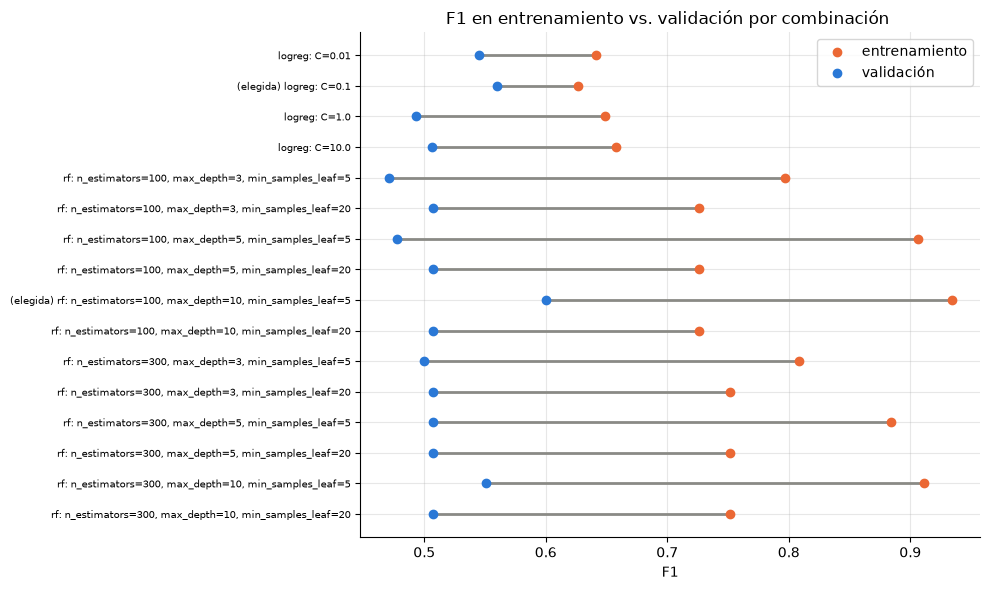

In [3]:
grilla = []
for replica in cfg.replicas:
    for params in param_grid(cfg["models"][replica]):
        m = fit_model(replica, params, cfg.seed, fit_df[FEATS], fit_df.y)
        grilla.append({"replica": replica, "params": ", ".join(f"{k}={v}" for k, v in params.items()),
                       "F1_entrenamiento": f1_value(fit_df.y, predict(m, fit_df[FEATS])),
                       "F1_validación": f1_value(val_df.y, predict(m, val_df[FEATS]))})
grilla = pd.DataFrame(grilla); grilla["brecha"] = grilla.F1_entrenamiento - grilla.F1_validación
elegidos = {r: select_hyperparameters(r, fit_df, val_df, cfg["models"][r], cfg.seed, FEATS) for r in cfg.replicas}

fig, ax = plt.subplots(figsize=(10, 6))
y = np.arange(len(grilla))
ax.hlines(y, grilla.F1_validación, grilla.F1_entrenamiento, color=GRIS)
ax.scatter(grilla.F1_entrenamiento, y, color=COLOR["B"], label="entrenamiento", zorder=3)
ax.scatter(grilla.F1_validación, y, color=COLOR["A"], label="validación", zorder=3)
etiquetas = [("(elegida) " if (r.replica, r.params) in {(k, ", ".join(f"{a}={b}" for a, b in p.items())) for k, (p, _) in elegidos.items()} else "") + f"{r.replica}: {r.params}" for r in grilla.itertuples()]
ax.set_yticks(y, etiquetas, fontsize=7.5); ax.invert_yaxis(); ax.set_xlabel("F1"); ax.legend()
ax.set_title("F1 en entrenamiento vs. validación por combinación "); plt.tight_layout()
for r, (p, v) in elegidos.items(): print(f"{r}: elegido {p} con F1 validación = {v:.3f}")

**Cómo leerlo:** cada fila es una combinación de hiperparámetros. El punto naranja es su F1 en los datos con que aprendió y el azul su F1 en datos nuevos. Cuanto más larga la línea gris, más sobreajuste.

**Qué concluimos:** La LR tiene brechas pequeñas (≈ 0,07 en la elegida). El RF profundo (`max_depth=10`) llega a F1 ≈ 0,93 en entrenamiento contra ≈ 0,60 en validación: **memoriza** (brecha ≈ 0,33). Además se eligió entre 12 combinaciones mirando solo 64 días, así que la ganadora puede serlo en parte por suerte (optimismo de selección).

In [4]:
import json
mv = pd.read_csv("results/model_versions.csv")
for r, (p, v) in elegidos.items():
    fila = mv[(mv.replica == r) & (mv.version == 1)].iloc[0]
    assert json.loads(fila.hyperparams) == p and np.isclose(fila.val_f1_hyperparam_selection, v)
print("OK: hiperparámetros y F1 de validación coinciden con results/model_versions.csv")

OK: hiperparámetros y F1 de validación coinciden con results/model_versions.csv


## 2. Modelo inicial y su envejecimiento (grupo A)

El modelo inicial se entrena con todo 2021 (211 días) y es la versión 1 de A, B y C. Abajo se compara su F1 en entrenamiento con su F1 en cada ventana de prueba.

replica,logreg,rf
tramo,,
2021 (entrenamiento),0.634,0.955
2022-H1,0.538,0.507
2022-H2,0.528,0.625
2023-H1,0.580,0.627
2023-H2,0.600,0.531
2024-H1,0.582,0.500
2024-H2,0.490,0.476
2025-H1,0.569,0.565
2025-H2,0.568,0.419


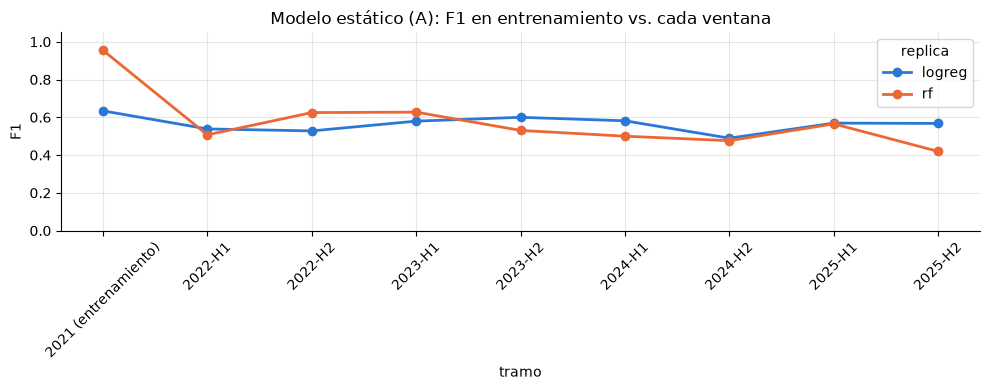

In [5]:
filas = []
for r in cfg.replicas:
    p = elegidos[r][0]
    m = fit_model(r, p, cfg.seed, initial_df[FEATS], initial_df.y)
    filas.append({"replica": r, "tramo": "2021 (entrenamiento)", "F1": f1_value(initial_df.y, predict(m, initial_df[FEATS]))})
    filas += [{"replica": r, "tramo": w.window_id, "F1": f1_value(w.data.y, predict(m, w.data[FEATS]))} for w in windows]
envej = pd.DataFrame(filas).pivot(index="tramo", columns="replica", values="F1")
envej = envej.loc[["2021 (entrenamiento)"] + [w.window_id for w in windows]]
ax = envej.plot(marker="o", color=[COLOR["A"], COLOR["B"]]); ax.set_ylabel("F1"); ax.set_ylim(0, 1.05)
ax.set_title("Modelo estático (A): F1 en entrenamiento vs. cada ventana"); ax.tick_params(axis="x", rotation=45); plt.tight_layout()
envej

**Cómo leerlo:** el primer punto es el F1 sobre los propios datos de entrenamiento; los siguientes, sobre cada semestre de prueba.

**Qué concluimos:** El RF pasa de 0,955 en entrenamiento a ≈ 0,4–0,6 en prueba: casi todo lo "aprendido" era memoria. La LR cae menos (de 0,63 a ≈ 0,5–0,6). En ninguno de los dos se ve una caída sostenida en el tiempo: el envejecimiento del modelo estático no es lineal.